In [49]:
# 1. Project Goals
The primary goal of this project is to investigate whether there is a relationship between a countries economic output (GDP) 
and the average life expectancy of its citizens. Specifically, this analysis aims to answer the following questions:
* Has life expectancy increased over time in the six nations?
* Has GDP increased over time in the six nations?
* Is there a correlation between GDP and life expectancy of a country?
* What is the average life expectancy in these nations?
* What is the distribution of life expectancy across the dataset?

## 2. Data
The dataset (`all_data.csv`) is sourced from the World Health Organization (WHO) and the World Bank.
* **Structure:** 96 rows and 4 columns (`Country`, `Year`, `Life expectancy at birth (years)`, and `GDP`).
* **Coverage:** Covers 6 nations (Chile, China, Germany, Mexico, United States, and Zimbabwe) over a 16-year period from 2000 to 2015.
* **Data Quality:** Clean dataset with zero missing or null values.

## 3. Analysis
To explore the data and answer the research questions, the analysis will follow four stages of Exploratory Data Analysis (EDA):
* **Data Inspection & Cleaning:** Verify data types, check for missing values, and rename long columns for cleaner code.
* **Summary Statistics:** Group data by country to calculate mean values for GDP and life expectancy, comparing them with side-by-side bar charts.
* **Distribution Analysis:** Use histograms and violin plots to examine skewness, overall spread, and country-level variance.
* **Time-Series & Correlation Analysis:** Plot line graphs to track changes from 2000 to 2015, and use scatter plots (both combined and faceted by country) alongside Pearson correlation coefficients to measure the relationship between wealth and longevity.

## 4. Evaluation
Findings will be evaluated by comparing visual patterns across both shared axes (to see global scale differences) and independent country subplots (to prevent large economies like the U.S. and China from masking trends in smaller economies like Zimbabwe and Chile). Statistical correlation scores ($r$) will confirm the strength of the linear relationship within each nation.

## 5. Output
The final deliverables for this project include:
* A well-documented **Jupyter Notebook** (`life_expectancy_gdp.ipynb`) containing clean Python code, visualizations, and Markdown explanations.
* A **GitHub repository** (or project summary) communicating key insights and limitations to both technical and non-technical audiences.


SyntaxError: invalid syntax (1764008164.py, line 2)

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [3]:
df = pd.read_csv('all_data.csv')
df.head()

,Country,Year,Life expectancy at birth (years),GDP
0,Chile,2000,77.3,7.786093e+10
1,Chile,2001,77.3,7.097992e+10
2,Chile,2002,77.8,6.973681e+10
3,Chile,2003,77.9,7.564346e+10
4,Chile,2004,78.0,9.921039e+10


In [5]:
#checking the data type and look for missing values
print(df.info())
print("\nunique Countries:", df.Country.unique())
print("Unique Years:", df.Year.unique())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 96 entries, 0 to 95
Data columns (total 4 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Country                           96 non-null     object 
 1   Year                              96 non-null     int64  
 2   Life expectancy at birth (years)  96 non-null     float64
 3   GDP                               96 non-null     float64
dtypes: float64(2), int64(1), object(1)
memory usage: 3.1+ KB
None

unique Countries: ['Chile' 'China' 'Germany' 'Mexico' 'United States of America' 'Zimbabwe']
Unique Years: [2000 2001 2002 2003 2004 2005 2006 2007 2008 2009 2010 2011 2012 2013
 2014 2015]


In [6]:
# Rename the long life expectancy column fpor easier typing
df.rename(columns={"Life expectancy at birth (years)": "Life_Expectancy"}, inplace=True)

In [7]:
#View summary statistics (mean, min, max)
df.describe()

,Year,Life_Expectancy,GDP
count,96.000000,96.000000,9.600000e+01
mean,2007.500000,72.789583,3.880499e+12
std,4.633971,10.672882,5.197561e+12
min,2000.000000,44.300000,4.415703e+09
25%,2003.750000,74.475000,1.733018e+11
50%,2007.500000,76.750000,1.280220e+12
75%,2011.250000,78.900000,4.067510e+12
max,2015.000000,81.000000,1.810000e+13


In [9]:
# Calcualte the average Life expectancy for each country
df.groupby('Country') ['Life_Expectancy'].mean()

Country
Chile                       78.94375
China                       74.26250
Germany                     79.65625
Mexico                      75.71875
United States of America    78.06250
Zimbabwe                    50.09375
Name: Life_Expectancy, dtype: float64

Calculating Average Life Expectancy and GDP


In [11]:
# Group by Country and calculate the average (mean) for Life Expectancy and GDP
country_means = df.groupby('Country')[['Life_Expectancy', 'GDP']].mean().reset_index()

# Sort by Life Expectancy from highest to lowest
country_means = country_means.sort_values(by='Life_Expectancy', ascending=False)
print(country_means)

                    Country  Life_Expectancy           GDP
2                   Germany         79.65625  3.094776e+12
0                     Chile         78.94375  1.697888e+11
4  United States of America         78.06250  1.407500e+13
3                    Mexico         75.71875  9.766506e+11
1                     China         74.26250  4.957714e+12
5                  Zimbabwe         50.09375  9.062580e+09


** Visualizing the Average with Bar Charts **

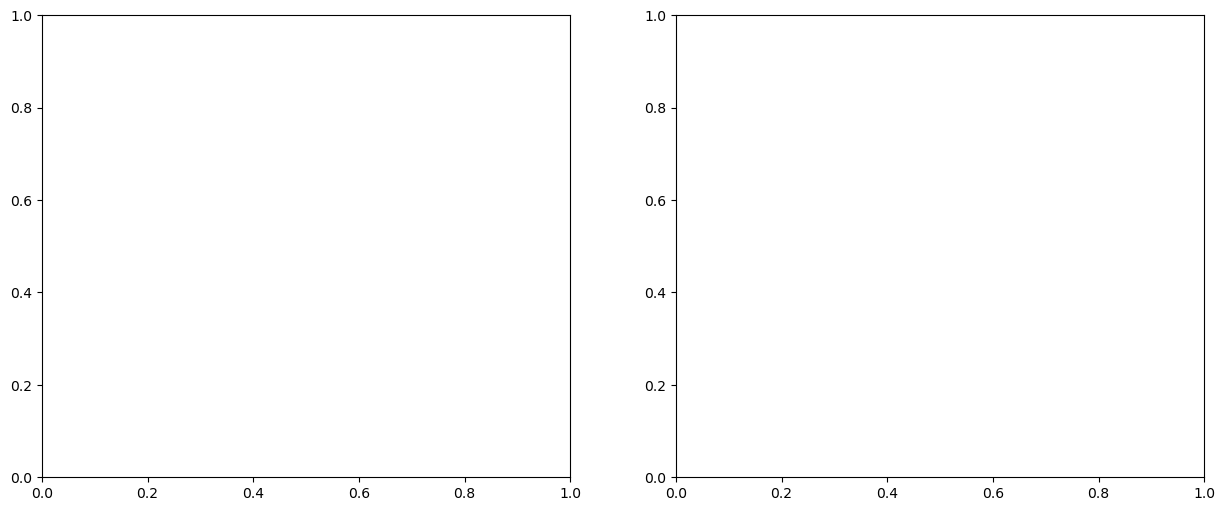

In [13]:
# Set up a figure with two side by side subplots
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

In [19]:
# Bar Chart 1: Average Life Expectancy
sns.barplot(ax=axes[0], data=country_means, x='Life_Expectancy', y='Country', hue='Country',  palette='viridis', legend=False)
axes[0].set_title('Average Life Expectancy by Country (2000-2015)')
axes[0].set_xlabel('Life Expectancy (Years)')


Text(0.5, 4.444444444444452, 'Life Expectancy (Years)')

In [21]:
# Bar Chart 2: Average GDP
sns.barplot(ax=axes[1], data=country_means, x='GDP', y='Country', hue='Country', palette='magma', legend=False)
axes[1].set_title('Average GDP by Country (2000-2015)')
axes[1].set_xlabel('GDP (in Trillions of USD)')

plt.tight_layout()
plt.show()

<Figure size 640x480 with 0 Axes>

** Overall Distribution (Histograms) **


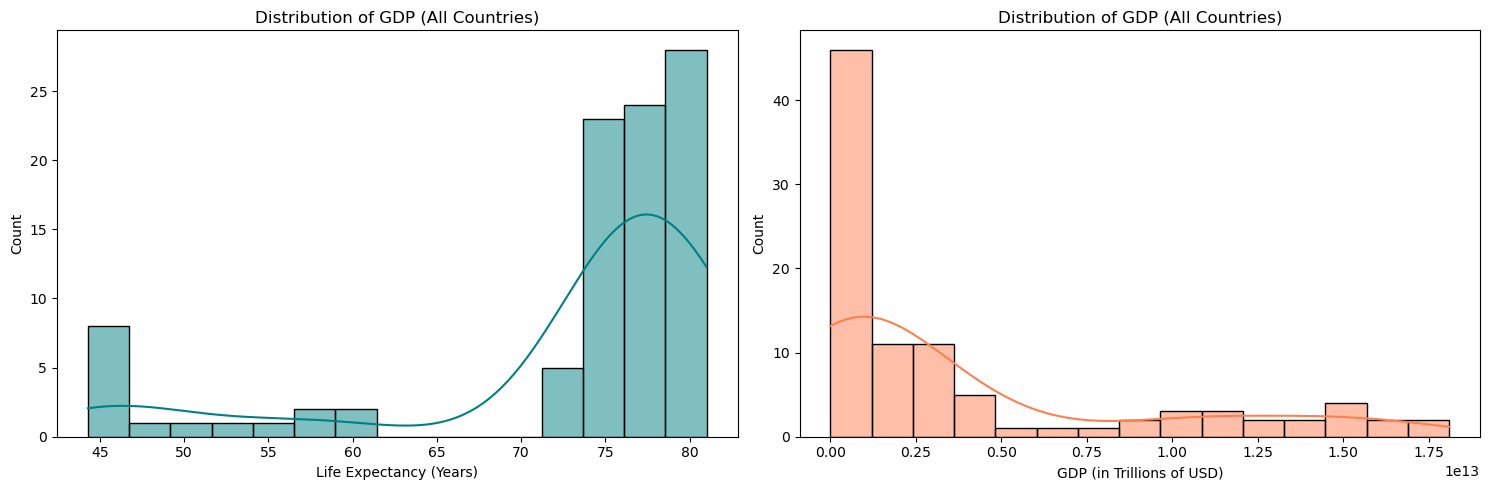

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Histogram 1 : Overall Life Expectancy
sns.histplot(ax=axes[0], data=df, x='Life_Expectancy', bins=15, kde=True, color='teal')
axes[0].set_title('Distribution of GDP (All Countries)')
axes[0].set_xlabel('Life Expectancy (Years)')

# Histogram 2: Overall GDP
sns.histplot(ax=axes[1], data=df, x='GDP', bins=15, kde=True, color='coral')
axes[1].set_title('Distribution of GDP (All Countries)')
axes[1].set_xlabel('GDP (in Trillions of USD)')

plt.tight_layout()
plt.show()

 ** Country-by-Country Spread (Violin Plots) **

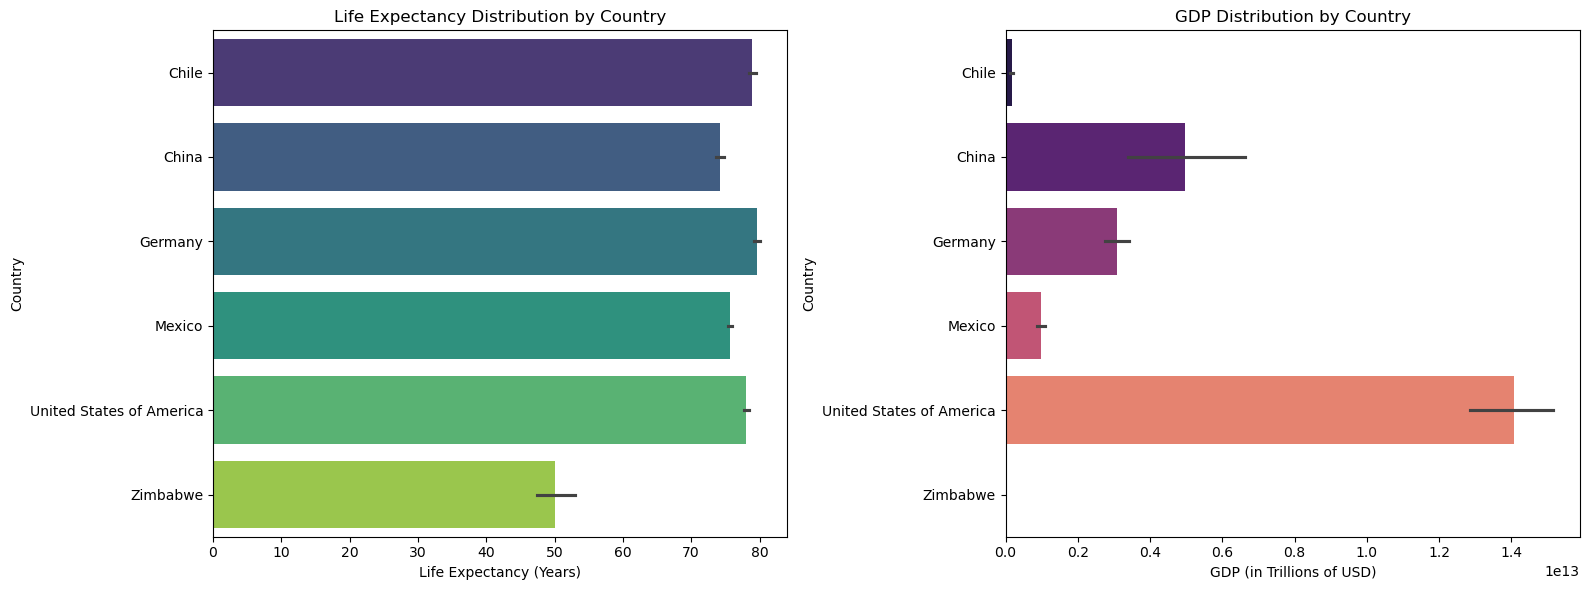

In [44]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Violin plot 1: Life Expectancy by Country
sns.barplot(ax=axes[0], data=df, x='Life_Expectancy', y='Country', hue='Country', palette='viridis', legend=False)
axes[0].set_title('Life Expectancy Distribution by Country')
axes[0].set_xlabel('Life Expectancy (Years)')

# Violin plot 2: GDP by country
sns.barplot(ax=axes[1], data=df, x='GDP', y='Country', hue='Country', palette='magma', legend=False)
axes[1].set_title('GDP Distribution by Country')
axes[1].set_xlabel('GDP (in Trillions of USD)')

plt.tight_layout()
plt.show()

In [ ]:
** Combined Line Charts (comparing all countries together) **

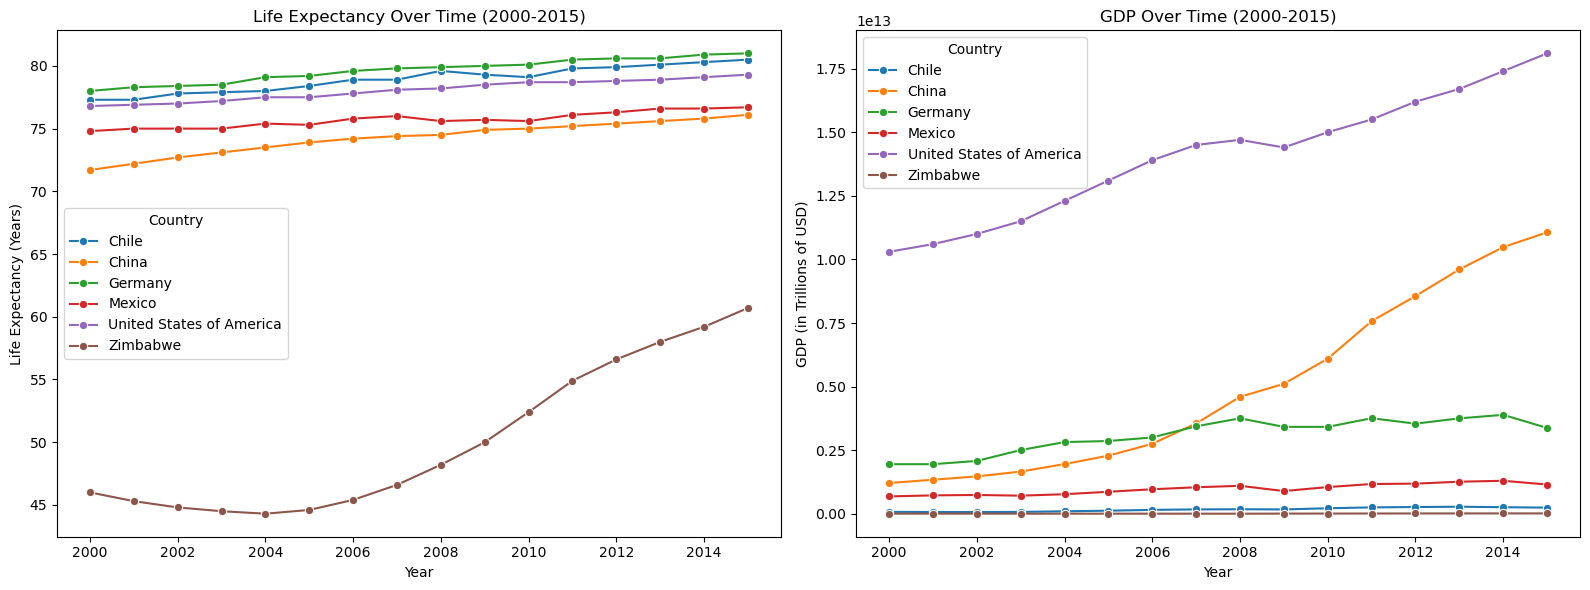

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Line Chart 1: Life Expectancy Over Time
sns.lineplot(ax=axes[0], data=df, x='Year', y='Life_Expectancy', hue='Country', marker='o')
axes[0].set_title('Life Expectancy Over Time (2000-2015)')
axes[0].set_ylabel('Life Expectancy (Years)')

# Line Charts 2: GDP Over Time
sns.lineplot(ax=axes[1], data=df, x='Year', y='GDP', hue='Country', marker='o')
axes[1].set_title('GDP Over Time (2000-2015)')
axes[1].set_ylabel('GDP (in Trillions of USD)')

plt.tight_layout()
plt.show()
             

** Scatter Plot **

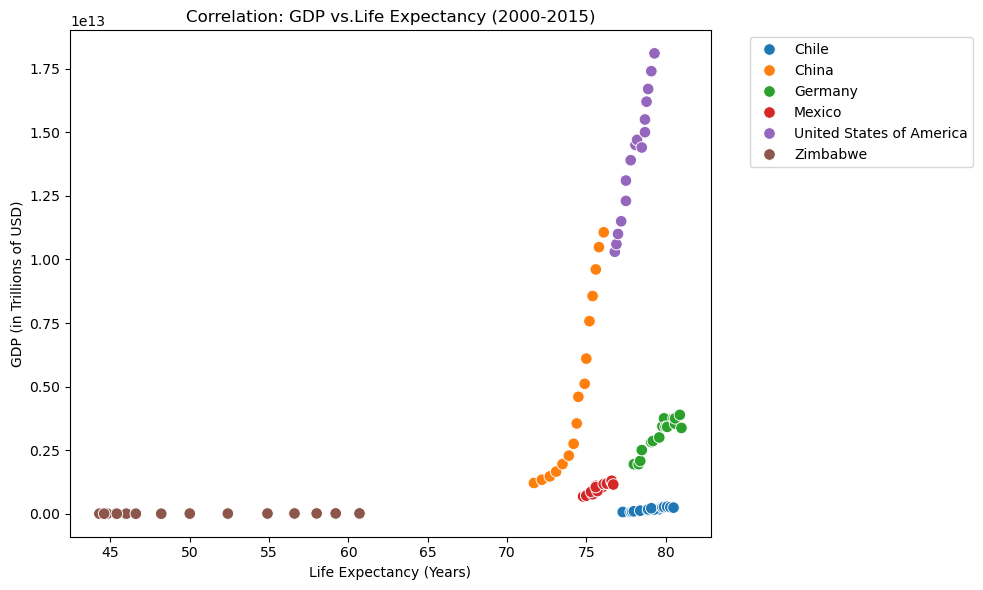

In [33]:
plt.figure(figsize=(10, 6))

# Scatter plot comparing Life Expectancy and GDP
sns.scatterplot(data=df, x='Life_Expectancy', y='GDP', hue='Country', s=70)

plt.title('Correlation: GDP vs.Life Expectancy (2000-2015)')
plt.xlabel('Life Expectancy (Years)')
plt.ylabel('GDP (in Trillions of USD)')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

** Has life expectancy increased over time in the six nations? **

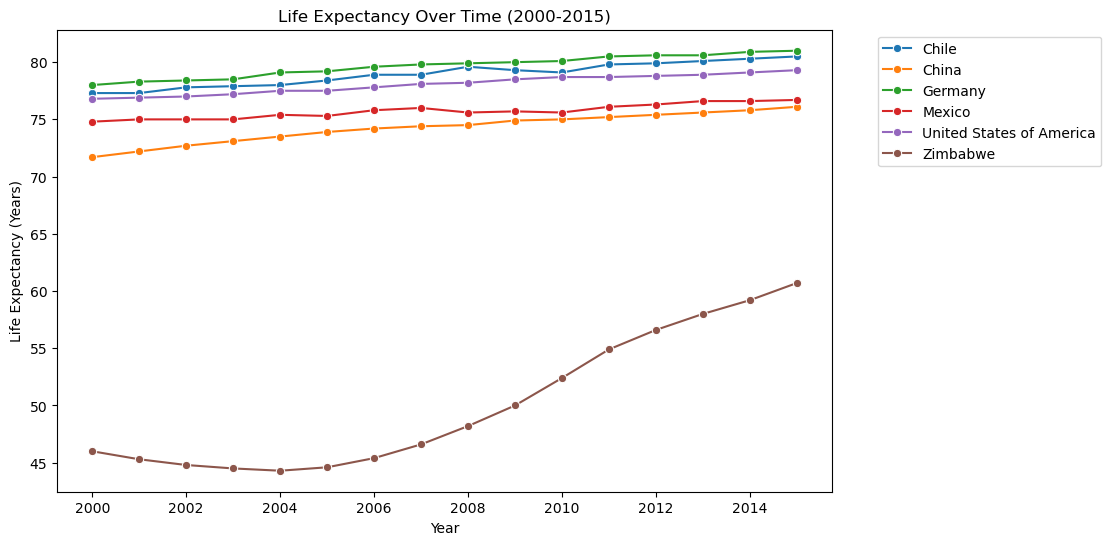

In [36]:
# Line plot of life expectancy over time
plt.figure(figsize=(10, 6))
sns.lineplot(data=df, x='Year', y='Life_Expectancy', hue='Country', marker='o')
plt.title('Life Expectancy Over Time (2000-2015)')
plt.ylabel('Life Expectancy (Years)')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()

** Yes, life expectancy increased across all six countries between 2000 and 2015. Most nations saw steady, gradual growth into the high 70s or low 80s.**

** Zimbabwe saw the most dramatic improvement. After dipping to a low of around 44.3 years in 2004, its life expectancy climbed sharply to 60.7 years by 2015. **

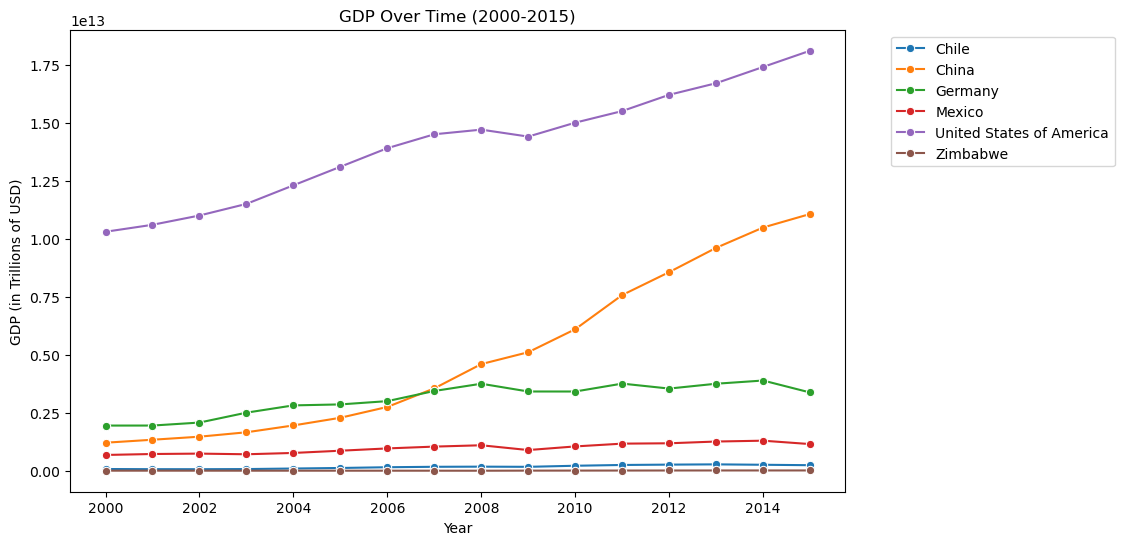

In [37]:
# Line plot of GDP over time 
plt.figure(figsize=(10, 6))
sns.lineplot(data=df, x='Year', y='GDP', hue='Country', marker='o')
plt.title('GDP Over Time (2000-2015)')
plt.ylabel('GDP (in Trillions of USD)')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()


** The GDP grew over time for every country in the datasest. However, the sacle of growth differs wildly between nations.
** China and the United States Experienced massive growth. China's GDP rose steeply from roughly 1.2 trillion in 2000 to over $11 trillion in 2015, while the U.S. grew from $10.3 trillion to $18.1 trillion.
** Smaller economies also grew proportionally. Chile, Mexico, and Zimbabwe saw steady increases, though their lines look flat on a shared chart because their total dollar amounts are much smaller tahn the U.s or China.

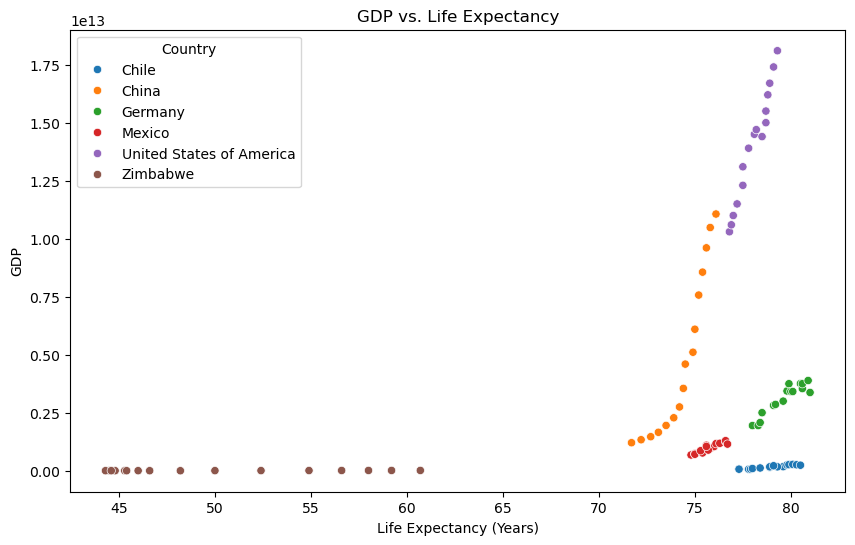

In [38]:
# Scatter plot comparing GDP and Life Expectancy
plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='Life_Expectancy', y='GDP', hue='Country')
plt.title('GDP vs. Life Expectancy')
plt.xlabel('Life Expectancy (Years)')
plt.show()

** There is a strong positive correlation between GDP and life expectancy. Within each individual country, as GDP increases over the years, life expectancy rises alongside it.
Higher wealth does not always mean teh highest expectancy. e.g, Chile has a much lower GDP than the United States, yet Chile maintains a slightly higher average life expectancy.

In [42]:
# Calculate and print average life expectancy by country
avg_le = df.groupby('Country')['Life_Expectancy'].mean().sort_values(ascending=False)
print(avg_le)

Country
Germany                     79.65625
Chile                       78.94375
United States of America    78.06250
Mexico                      75.71875
China                       74.26250
Zimbabwe                    50.09375
Name: Life_Expectancy, dtype: float64


** Five of the six nations have an average life expectancy between 75 and 80 years. gErmany leads the group, while zimbabwe falls significantly behind the rest.

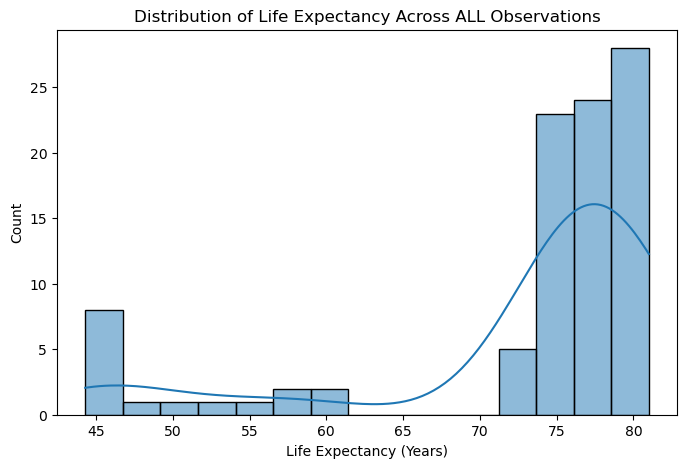

In [43]:
# Histogram showing the distribution of Life Expectancy
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x='Life_Expectancy', bins=15, kde=True)
plt.title('Distribution of Life Expectancy Across ALL Observations')
plt.xlabel('Life Expectancy (Years)')
plt.show()

** The overall dataset is heavily left-skewed. Most data points cluster tightly between 74 and 81 years, while Zim,babwe's values stretch the tail down into 44 to 60 years range.
** Zimbabwe has the widest spread. While countries like germany and thge U.S stayed within a narrow 2-to-3-year range over the 15-year period , Zimbabwe's values span over 16 years due to its rapid recovery.

In [ ]:
## Conclusion

Looking through the data from 2000 to 2015, it becomes clear that a countries economic growth and the health of its citizens are closely tied together. Across all six nations we explored, both GDP and life expectancy climbed steadily over the 16-year period, showing a strong positive correlation within every single country.

That said, digging a little deeper revealed a few surprising nuances:

* **Money helps, especially early on, but it isn't everything:
** While every nation saw longer lifespans as its economy grew, the biggest jumps happened in developing economies. Zimbabwe is the standout story here—after hitting a rough low around 2004, its life expectancy rebounded by more than 16 years as its economy began recovering.
* **The richest country doesn't always live the longest:
** Even though the United States had by far the largest GDP in the dataset, countries like Germany and Chile consistently achieved slightly higher average life expectancies on much smaller budgets. This suggests that once a country reaches a certain level of wealth, factors like healthcare access, diet, and public policy matter just as much as raw economic output.
* **Scale can hide important stories:** Looking at all six countries on a single chart initially made smaller economies like Chile and Zimbabwe look stagnant next to giants like the U.S. and China. Breaking the data out into individual country views was essential to see that those nations were actually making huge strides of their own.

### What Could We Explore Next?
Because this dataset only tracks six countries up to 2015, a great next step would be pulling in more recent data to see how global events—like the COVID-19 pandemic—impacted these trends. Adding variables like healthcare spending per capita, education rates, or income inequality would also help explain why countries like Chile outperform wealthier peers in longevity.